In [1]:
!wget -O creditcard.csv "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

--2026-11-17 13:48:31--  https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 34.3.1.27, 34.144.171.27, 104.154.125.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|34.3.1.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 150828752 (144M) [text/csv]
Saving to: ‘creditcard.csv’

creditcard.csv      100%[===================>] 143.84M   162MB/s    in 0.9s    

2026-11-17 13:48:32 (162 MB/s) - ‘creditcard.csv’ saved [150828752/150828752]



DATASET INFORMATION
Dataset Shape: (284807, 31)

First 5 Records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Missing Values:
0

CLASS DISTRIBUTION
Class
0    284315
1       492
Name: count, dtype: int64

Class Percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Normal Transactions: 284315
Fraudulent Transactions: 492


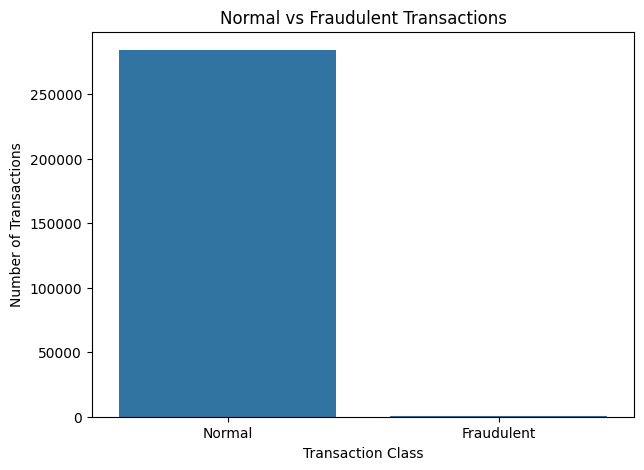


Feature scaling completed.

BEFORE SMOTE
Class
0    227451
1       394
Name: count, dtype: int64

AFTER SMOTE
Class
0    227451
1    227451
Name: count, dtype: int64


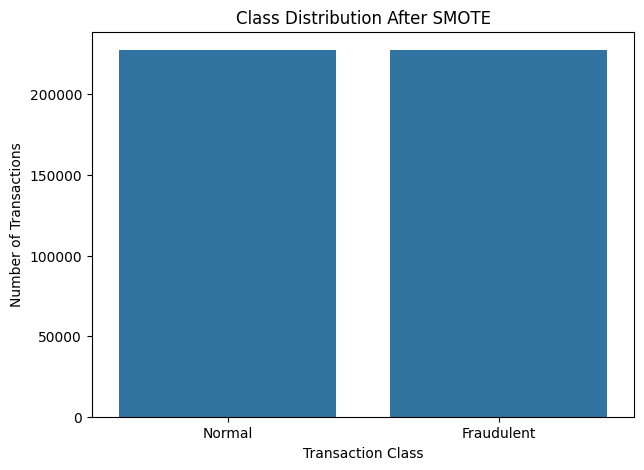


TRAINING RANDOM FOREST
Random Forest model trained successfully.

Predictions completed.

First 20 Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

RANDOM FOREST MODEL EVALUATION
Accuracy  : 0.9995
Precision : 0.8454
Recall    : 0.8367
F1-Score  : 0.8410
ROC-AUC   : 0.9731

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962


Confusion Matrix:
[[56849    15]
 [   16    82]]


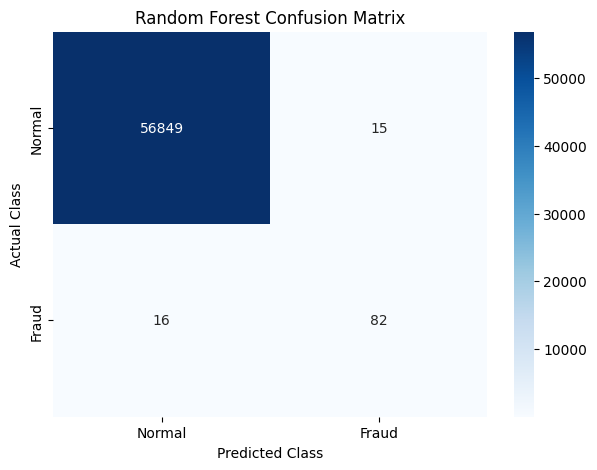


Top 10 Important Features:


,Feature,Importance
14,V14,0.195607
10,V10,0.110459
4,V4,0.106133
12,V12,0.095085
17,V17,0.085002
3,V3,0.060455
11,V11,0.056356
16,V16,0.043757
2,V2,0.036986
9,V9,0.026203


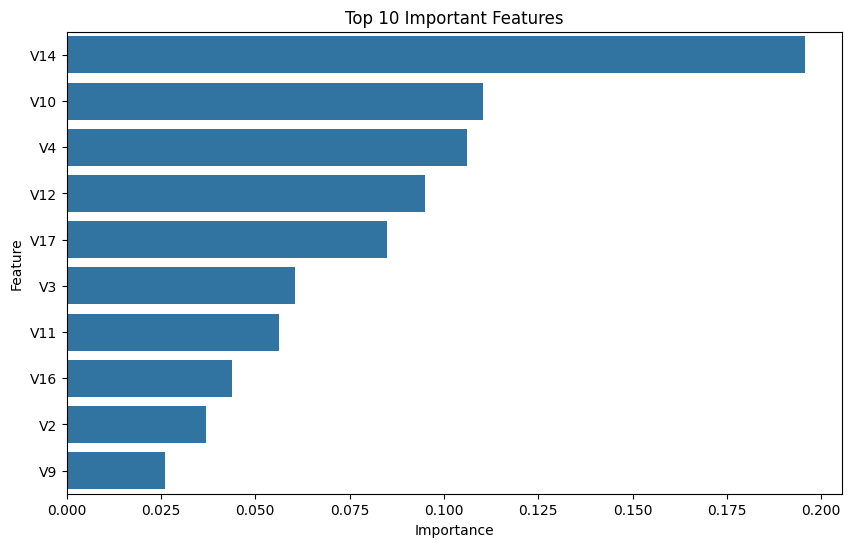


Model saved as:
fraud_detection_random_forest.pkl

Scaler saved as:
fraud_detection_scaler.pkl

CREDIT CARD FRAUD DETECTION COMPLETED


In [2]:
# ============================================================
# CREDIT CARD FRAUD DETECTION SYSTEM
# Random Forest + SMOTE
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE


# ============================================================
# STEP 2: LOAD DATASET
# ============================================================

data = pd.read_csv("creditcard.csv")

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("Dataset Shape:", data.shape)

print("\nFirst 5 Records:")
display(data.head())

print("\nMissing Values:")
print(data.isnull().sum().sum())


# ============================================================
# STEP 3: CHECK CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

class_counts = data["Class"].value_counts()

print(class_counts)

print("\nClass Percentages:")
print(data["Class"].value_counts(normalize=True) * 100)

print("\nNormal Transactions:", class_counts[0])
print("Fraudulent Transactions:", class_counts[1])


# Visualization

plt.figure(figsize=(7, 5))

sns.countplot(
    x="Class",
    data=data
)

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks(
    [0, 1],
    ["Normal", "Fraudulent"]
)

plt.show()


# ============================================================
# STEP 4: FEATURE SCALING
# ============================================================

# Separate features and target

X = data.drop("Class", axis=1)
y = data["Class"]


# Split BEFORE scaling

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# Scale Time and Amount using training data only

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Amount"] = scaler.fit_transform(
    X_train[["Amount"]]
)

X_test["Amount"] = scaler.transform(
    X_test[["Amount"]]
)

X_train["Time"] = scaler.fit_transform(
    X_train[["Time"]]
)

X_test["Time"] = scaler.transform(
    X_test[["Time"]]
)

print("\nFeature scaling completed.")


# ============================================================
# STEP 5: APPLY SMOTE AND PREPARE DATA
# ============================================================

print("\n" + "=" * 60)
print("BEFORE SMOTE")
print("=" * 60)

print(y_train.value_counts())


smote = SMOTE(
    random_state=42
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train
)


print("\n" + "=" * 60)
print("AFTER SMOTE")
print("=" * 60)

print(y_train_resampled.value_counts())


# Visualization after SMOTE

plt.figure(figsize=(7, 5))

sns.countplot(
    x=y_train_resampled
)

plt.title("Class Distribution After SMOTE")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks(
    [0, 1],
    ["Normal", "Fraudulent"]
)

plt.show()


# ============================================================
# STEP 6: TRAIN RANDOM FOREST MODEL
# ============================================================

print("\n" + "=" * 60)
print("TRAINING RANDOM FOREST")
print("=" * 60)


rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Random Forest model trained successfully.")


# ============================================================
# STEP 7: PREDICTIONS
# ============================================================

y_pred = rf_model.predict(X_test)

# Probability of fraud
y_probability = rf_model.predict_proba(X_test)[:, 1]

print("\nPredictions completed.")

print("\nFirst 20 Predictions:")
print(y_pred[:20])


# ============================================================
# STEP 8: MODEL EVALUATION
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)


print("\n" + "=" * 60)
print("RANDOM FOREST MODEL EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")


# Classification Report

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Fraud"
        ]
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Fraud"
    ],
    yticklabels=[
        "Normal",
        "Fraud"
    ]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


# ============================================================
# FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 10 Important Features:")
display(feature_importance.head(10))


plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()


# ============================================================
# SAVE MODEL
# ============================================================

import joblib

joblib.dump(
    rf_model,
    "fraud_detection_random_forest.pkl"
)

joblib.dump(
    scaler,
    "fraud_detection_scaler.pkl"
)

print("\nModel saved as:")
print("fraud_detection_random_forest.pkl")

print("\nScaler saved as:")
print("fraud_detection_scaler.pkl")

print("\n" + "=" * 60)
print("CREDIT CARD FRAUD DETECTION COMPLETED")
print("=" * 60)

In [3]:
import pandas as pd

data = pd.read_csv("creditcard.csv")

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

    